# 01 · Análisis exploratorio de pills-sxdht

Inspección del archivo COCO original de [Hugging Face](https://huggingface.co/datasets/Francesco/pills-sxdht). El guion indica siete clases. Distinguimos entre categorías declaradas, categorías usadas y número de imágenes que contienen cada clase.

Ejecuta las celdas en orden desde JupyterLab. El kernel puede iniciarse en la raíz del repositorio o en `notebooks/`. Las comprobaciones y visualizaciones son de solo lectura.

In [1]:
import hashlib
import json
import math
import runpy
from collections import Counter, defaultdict
from html import escape
from io import BytesIO
from itertools import combinations
from pathlib import Path
from random import Random

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from PIL import Image

SEED = 2026
cwd = Path.cwd()
repo = next(
    (path for path in (cwd, *cwd.parents) if (path / "scripts/download_dataset.py").is_file()),
    None,
)
if repo is None:
    raise FileNotFoundError("Inicia JupyterLab desde la raíz del repositorio.")

download = runpy.run_path(str(repo / "scripts/download_dataset.py"))
root = download["DESTINATION"]
parts = download["SPLITS"]
annotation_name = download["ANNOTATIONS"]
if not root.is_dir():
    raise FileNotFoundError("Falta data/pills-sxdht. Ejecuta uv run --locked python scripts/download_dataset.py.")

cocos = {}
for split in parts:
    path = root / split / annotation_name
    try:
        cocos[split] = json.loads(path.read_text(encoding="utf-8"))
    except (OSError, ValueError) as error:
        raise ValueError(f"No se pudo leer {split}/{annotation_name}: {error}") from error
    if not isinstance(cocos[split], dict) or any(
        not isinstance(cocos[split].get(key), list) for key in ("images", "annotations", "categories")
    ):
        raise ValueError(f"{path.name} de {split} no contiene las tres listas COCO esperadas.")

print("Revisión de referencia:", download["REVISION"])

Revisión de referencia: f599e8469b24e0474723fed566bca04c59c477f0


## A · Estructura e integridad

La unidad de inspección es la imagen dentro de su partición, ya que los IDs COCO son locales a cada JSON. Comparamos nombres, IDs y dimensiones, verificamos y decodificamos cada JPEG y comprobamos las referencias de cada anotación. Las cajas COCO son `[x, y, ancho, alto]`. Usamos las dimensiones decodificadas y una tolerancia de \(10^{-6}\) píxeles en los bordes. Una caja inválida queda registrada y se omite únicamente en los cálculos geométricos y en el dibujo.

En la misma lectura recogemos descriptores visuales escalares y huellas de cada imagen. Conservamos las huellas y los descriptores, y liberamos los píxeles al terminar cada imagen.

In [2]:
issues = []
file_rows = []
image_rows = []
object_rows = []
category_rows = []
split_rows = []
rgb_histograms = defaultdict(lambda: np.zeros((3, 32)))

def flag(split, issue, item):
    issues.append({"partición": split, "incidencia": issue, "elemento": item})

def flag_repeated(records, field, label, split):
    values = (row.get(field) for row in records)
    for value, count in Counter(v for v in values if v is None or type(v) in (int, str)).items():
        if value is None or count > 1:
            flag(split, f"{label} sin {field} o repetido", f"{value!r} (×{count})")

def describe_image(path, split):
    with Image.open(path) as source:
        source.verify()
    with Image.open(path) as source:
        source.load()
        image_format = source.format
        rgb = source.convert("RGB")
    width, height = rgb.size
    pixels = np.asarray(rgb)
    gray = rgb.convert("L")
    luma = np.asarray(gray, dtype=np.int16)
    thumb = np.asarray(gray.resize((9, 8), Image.Resampling.LANCZOS))
    dhash = int.from_bytes(np.packbits(thumb[:, 1:] > thumb[:, :-1]).tobytes(), "big")
    for channel in range(3):
        histogram = np.bincount((pixels[..., channel] // 8).ravel(), minlength=32)
        rgb_histograms[split][channel] += histogram / histogram.sum()
    return {
        "split": split, "file_name": path.name, "width": width, "height": height,
        "format": image_format, "size_kib": path.stat().st_size / 1024,
        "brightness": luma.mean(), "contrast": luma.std(),
        "gradient": (np.abs(np.diff(luma, axis=0)).mean()
                     + np.abs(np.diff(luma, axis=1)).mean()) / 2 if min(rgb.size) > 1 else np.nan,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "pixel_hash": hashlib.sha256(f"{width}x{height}:".encode() + pixels.tobytes()).hexdigest(),
        "dhash": dhash,
    }

def box_geometry(bbox, size):
    if not isinstance(bbox, list) or len(bbox) != 4 or any(
        type(value) not in (int, float) or not math.isfinite(value) for value in bbox
    ):
        return None, "caja no numérica, no finita o con longitud distinta de 4"
    x, y, w, h = bbox
    if w <= 0 or h <= 0:
        return None, "caja con ancho o alto no positivo"
    if size is None:
        return None, "caja sin dimensiones de imagen verificables"
    width, height = size
    tol = 1e-6
    if x < -tol or y < -tol or x + w > width + tol or y + h > height + tol:
        return None, "caja fuera de los límites"
    return (x, y, w, h, w * h / (width * height), w / h), None

for filename in sorted(download["DOCUMENTS"]):
    if not (root / filename).is_file():
        flag("global", "falta un documento del archivo original", filename)
for folder in sorted(path.name for path in root.iterdir() if path.is_dir() and path.name not in parts):
    flag("global", "partición inesperada", folder)

for split, coco in cocos.items():
    folder = root / split
    files = {path.name: path for path in sorted(folder.iterdir())
             if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}}
    decoded = {}
    for name, path in files.items():
        try:
            row = describe_image(path, split)
        except (OSError, ValueError, SyntaxError) as error:
            flag(split, "imagen dañada o ilegible", f"{name}: {error}")
            continue
        decoded[name] = row
        file_rows.append(row)
        if row["format"] != "JPEG":
            flag(split, "formato distinto de JPEG", name)

    records = {}
    for key, label in (("images", "imagen"), ("annotations", "anotación"), ("categories", "categoría")):
        records[key] = []
        for index, row in enumerate(coco[key]):
            if isinstance(row, dict):
                records[key].append(row)
            else:
                flag(split, f"registro de {label} no válido", f"{key}[{index}]")
        flag_repeated(records[key], "id", label, split)
    flag_repeated(records["images"], "file_name", "imagen", split)
    images = {row.get("id"): row for row in records["images"] if type(row.get("id")) is int}
    categories = {row.get("id"): row.get("name") for row in records["categories"]
                  if type(row.get("id")) is int and isinstance(row.get("name"), str)}
    for category in records["categories"]:
        if type(category.get("id")) is not int or not isinstance(category.get("name"), str):
            flag(split, "declaración de categoría inválida", repr(category))
    category_rows.extend({"split": split, "category_id": cid, "name": name}
                         for cid, name in categories.items())
    names = {row.get("file_name") for row in records["images"] if isinstance(row.get("file_name"), str)}
    for name in sorted(names - files.keys()):
        flag(split, "imagen referenciada ausente", name)
    for name in sorted(files.keys() - names):
        flag(split, "imagen sin registro COCO", name)
    for image in records["images"]:
        ident, name = image.get("id"), image.get("file_name")
        if type(ident) is not int or not isinstance(name, str):
            flag(split, "registro de imagen inválido", repr(image))
            continue
        pixel = decoded.get(name)
        w, h = image.get("width"), image.get("height")
        if type(w) is not int or type(h) is not int or min(w, h) <= 0:
            flag(split, "dimensiones COCO inválidas", name)
        elif pixel and (w, h) != (pixel["width"], pixel["height"]):
            flag(split, "dimensiones COCO distintas del JPEG", f"{name}: JSON {w}×{h}, JPEG {pixel['width']}×{pixel['height']}")
        image_rows.append({
            "split": split, "image_id": ident, "file_name": name, "readable": pixel is not None,
            "width": pixel["width"] if pixel else w, "height": pixel["height"] if pixel else h,
        })

    seen_boxes = set()
    for annotation in records["annotations"]:
        ident = annotation.get("id")
        iid, cid = annotation.get("image_id"), annotation.get("category_id")
        image = images.get(iid) if type(iid) is int else None
        if type(ident) is not int:
            flag(split, "ID de anotación inválido", repr(ident))
        if image is None:
            flag(split, "anotación con image_id desconocido", f"{ident}: {iid}")
        known_category = type(cid) is int and cid in categories
        if not known_category:
            flag(split, "anotación con category_id desconocido", f"{ident}: {cid}")
        name = image.get("file_name") if image else None
        pixels = decoded.get(name) if isinstance(name, str) else None
        size = (pixels["width"], pixels["height"]) if pixels else None
        if size is None and image:
            w, h = image.get("width"), image.get("height")
            if type(w) is int and type(h) is int and min(w, h) > 0:
                size = (w, h)
        geometry, error = box_geometry(annotation.get("bbox"), size)
        if error:
            flag(split, error, str(ident))
        area = annotation.get("area")
        if type(area) not in (int, float) or not math.isfinite(area) or area <= 0:
            flag(split, "campo area inválido", str(ident))
        if geometry is not None and image is not None and known_category:
            key = (iid, cid, *geometry[:4])
            if key in seen_boxes:
                flag(split, "caja repetida para la misma imagen y clase", str(ident))
            seen_boxes.add(key)
        object_rows.append({
            "split": split, "annotation_id": ident,
            "image_id": iid if type(iid) is int else None,
            "category_id": cid if type(cid) is int else None,
            "known_category": known_category, "known_image": image is not None,
            "geometry": geometry,
        })

    split_rows.append({
        "split": split, "esperadas": parts[split], "JPEG/archivos de imagen": len(files),
        "decodificadas": len(decoded), "registros COCO": len(coco["images"]),
        "anotaciones": len(coco["annotations"]),
    })
    if len(files) != parts[split] or len(coco["images"]) != parts[split]:
        flag(split, "recuento distinto al de la revisión del descargador", str(parts[split]))

images = pd.DataFrame(image_rows)
objects = pd.DataFrame(object_rows)
image_files = pd.DataFrame(file_rows)
declared = pd.DataFrame(category_rows)
for cid, names in declared.groupby("category_id")["name"]:
    if names.nunique() > 1:
        flag("global", "nombre de categoría distinto según la partición", str(cid))
for split, group in declared.groupby("split"):
    if set(group["category_id"]) != set(declared["category_id"]):
        flag(split, "lista de IDs de categoría distinta", split)

audit = pd.DataFrame(split_rows).set_index("split")
issue_table = pd.DataFrame(issues, columns=["partición", "incidencia", "elemento"])
display(audit)
if issue_table.empty:
    print("No se encontraron incidencias con las comprobaciones anteriores.")
else:
    display(issue_table.groupby(["partición", "incidencia"]).size().rename("casos").to_frame())
    display(issue_table.head(20))

,esperadas,JPEG/archivos de imagen,decodificadas,registros COCO,anotaciones
split,,,,,
train,316,316,316,316,351
valid,90,90,90,90,98
test,45,45,45,45,47


No se encontraron incidencias con las comprobaciones anteriores.


In [3]:
category_names = declared.groupby("category_id")["name"].first().sort_index()
class_ids = category_names.index
labels = {cid: f"{cid} · {name}" for cid, name in category_names.items()}

def class_counts(rows):
    return (rows.groupby(["category_id", "split"]).size().unstack(fill_value=0)
            .reindex(index=class_ids, columns=parts, fill_value=0))

category_counts = class_counts(objects[objects["known_category"]])
image_presence = class_counts(
    objects[objects["known_category"] & objects["known_image"]]
    .drop_duplicates(["category_id", "split", "image_id"])
)
used_ids = category_counts.index[category_counts.sum(axis=1) > 0]
category_report = declared.pivot_table(
    index="category_id", columns="split", values="name", aggfunc="first"
).reindex(columns=parts)
display(category_report.add_prefix("nombre en ").join(category_counts.add_prefix("objetos en ")))
print(f"Guion: 7 clases. COCO: {len(class_ids)} IDs declarados, {len(used_ids)} utilizados "
      f"({', '.join(map(str, used_ids))}).")
print("IDs declarados sin anotaciones:", sorted(set(class_ids) - set(used_ids)))

split,nombre en train,nombre en valid,nombre en test,objetos en train,objetos en valid,objetos en test
category_id,,,,,,
0,pills,pills,pills,0,0,0
1,Cipro 500,Cipro 500,Cipro 500,79,26,8
2,Ibuphil 600 mg,Ibuphil 600 mg,Ibuphil 600 mg,1,1,0
3,Ibuphil Cold 400-60,Ibuphil Cold 400-60,Ibuphil Cold 400-60,55,10,7
4,Xyzall 5mg,Xyzall 5mg,Xyzall 5mg,57,10,5
5,blue,blue,blue,42,11,6
6,pink,pink,pink,35,15,8
7,red,red,red,40,15,5
8,white,white,white,42,10,8


Guion: 7 clases. COCO: 9 IDs declarados, 8 utilizados (1, 2, 3, 4, 5, 6, 7, 8).
IDs declarados sin anotaciones: [0]


### Imágenes repetidas

SHA-256 detecta archivos idénticos. Una segunda huella compara píxeles RGB decodificados y dimensiones, y puede detectar copias con distintos metadatos JPEG. Para sugerir duplicados visuales usamos dHash de 64 bits sobre una miniatura en gris. Marcamos pares a distancia de Hamming ≤ 4 y mostramos primero los candidatos entre particiones. Fondos parecidos pueden producir falsos positivos, y recortes o giros pueden ocultar duplicados. Las coincidencias de dHash requieren inspección visual.

In [4]:
def repeated_groups(column):
    return [group for _, group in image_files.groupby(column, sort=False) if len(group) > 1]

for column, description in (("sha256", "Archivos idénticos"), ("pixel_hash", "Píxeles idénticos")):
    groups = repeated_groups(column)
    cross = sum(group["split"].nunique() > 1 for group in groups)
    print(f"{description}: {len(groups)} grupos, {cross} entre particiones.")
    if groups:
        display(pd.DataFrame([
            {"entre particiones": group["split"].nunique() > 1,
             "archivos": " | ".join(f"{r.split}/{r.file_name}" for r in group.itertuples())}
            for group in groups
        ]).sort_values("entre particiones", ascending=False).head(12))

visual_pairs = []
for a, b in combinations(image_files.itertuples(index=False), 2):
    distance = (a.dhash ^ b.dhash).bit_count()
    if a.pixel_hash != b.pixel_hash and distance <= 4:
        visual_pairs.append({"entre particiones": a.split != b.split, "distancia": distance,
                             "imagen A": f"{a.split}/{a.file_name}",
                             "imagen B": f"{b.split}/{b.file_name}"})
visual_cross = sum(pair["entre particiones"] for pair in visual_pairs)
print(f"Candidatos dHash: {len(visual_pairs)} pares, {visual_cross} entre particiones.")
if visual_pairs:
    display(pd.DataFrame(visual_pairs).sort_values(
        ["entre particiones", "distancia"], ascending=[False, True]
    ).head(12))

Archivos idénticos: 0 grupos, 0 entre particiones.
Píxeles idénticos: 0 grupos, 0 entre particiones.
Candidatos dHash: 6 pares, 3 entre particiones.


,entre particiones,distancia,imagen A,imagen B
2,True,4,train/20210702_164707_jpg.rf.01b371de7a2f571ac...,test/20210702_164700_jpg.rf.d46994bef2b2f37f6a...
3,True,4,train/20210702_165810_jpg.rf.68b186c9a68c27a45...,valid/20210702_165640_jpg.rf.56747ec117d50e75b...
4,True,4,train/20210702_165823_jpg.rf.980b49434cbf383f7...,valid/20210702_165651_jpg.rf.ed6f8ad55923101ea...
1,False,3,train/20210702_164234_jpg.rf.77d461fe0a23d36c6...,train/20210702_164239_jpg.rf.963fc755db0c79c86...
0,False,4,train/20210702_161106_jpg.rf.83e00902cf836edb9...,train/20210702_161107_jpg.rf.7d13a87a45fea2a80...
5,False,4,train/20210729_180637_jpg.rf.59b104f42437948b4...,train/20210729_180650_jpg.rf.7c88e895b18af0825...


In [5]:
def show_dhash_pairs(pairs):
    if not pairs:
        print("No hay pares candidatos a similitud perceptual por dHash.")
        return

    ordered = sorted(pairs, key=lambda pair: (not pair["entre particiones"], pair["distancia"]))
    index_picker = widgets.IntSlider(
        min=1, max=len(ordered), description="Par", continuous_update=False
    )
    info = widgets.HTML()
    captions = [widgets.HTML(), widgets.HTML()]
    pictures = [widgets.Image(layout=widgets.Layout(width="min(100%, 400px)")) for _ in captions]
    panels = [
        widgets.VBox([caption, picture], layout=widgets.Layout(flex="1 1 0", min_width="0"))
        for caption, picture in zip(captions, pictures)
    ]

    def render(_=None):
        pair = ordered[index_picker.value - 1]
        location = "Entre particiones" if pair["entre particiones"] else "Misma partición"
        info.value = (
            f"<b>{location}</b> · Par {index_picker.value}/{len(ordered)} · "
            f"Distancia de Hamming: {pair['distancia']}"
        )
        for key, caption, picture in zip(("imagen A", "imagen B"), captions, pictures):
            image_path = pair[key]
            data = (root / image_path).read_bytes()
            with Image.open(BytesIO(data)) as source:
                picture.format = source.format.lower()
            picture.value = data
            caption.value = f'<div style="overflow-wrap: anywhere">{escape(image_path)}</div>'

    index_picker.observe(render, names="value")
    render()
    display(widgets.VBox([
        widgets.HTML(
            "<b>Candidatos a similitud perceptual (dHash)</b><br>"
            "Los pares tienen píxeles distintos. Una distancia baja señala un candidato "
            "para inspección visual."
        ),
        index_picker,
        info,
        widgets.HBox(panels),
    ]))


show_dhash_pairs(visual_pairs)

## B · Distribución de los datos

Contamos objetos anotados e imágenes distintas por clase. Una imagen puede contribuir a varias clases, por lo que los porcentajes por clase no suman necesariamente 100 %. Para tamaños y proporciones usamos cajas válidas. El tamaño es el área de la caja respecto al área de la imagen. Usamos umbrales descriptivos propios: pequeña < 1 %, mediana ≥ 1 % y < 10 %, grande ≥ 10 %. Estos cortes no son los umbrales absolutos de COCO.

split,imágenes en train,imágenes en valid,imágenes en test,% en train,% en valid,% en test
category_id,,,,,,
0,0,0,0,0.0,0.0,0.0
1,79,24,8,25.0,26.7,17.8
2,1,1,0,0.3,1.1,0.0
3,55,10,7,17.4,11.1,15.6
4,56,10,5,17.7,11.1,11.1
5,42,11,6,13.3,12.2,13.3
6,35,15,8,11.1,16.7,17.8
7,40,15,5,12.7,16.7,11.1
8,42,10,8,13.3,11.1,17.8


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,316.0,1.11,0.45,1.0,1.0,1.0,1.0,4.0
valid,90.0,1.09,0.51,1.0,1.0,1.0,1.0,5.0
test,45.0,1.04,0.30,1.0,1.0,1.0,1.0,3.0


Categorías con 1 a 5 objetos en total: {'2 · Ibuphil 600 mg': 2}
Categorías activas ausentes en alguna partición: {'2 · Ibuphil 600 mg': ['test']}


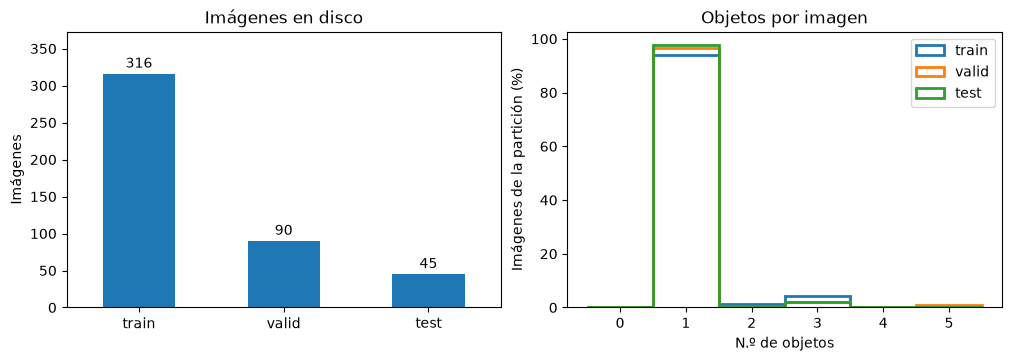

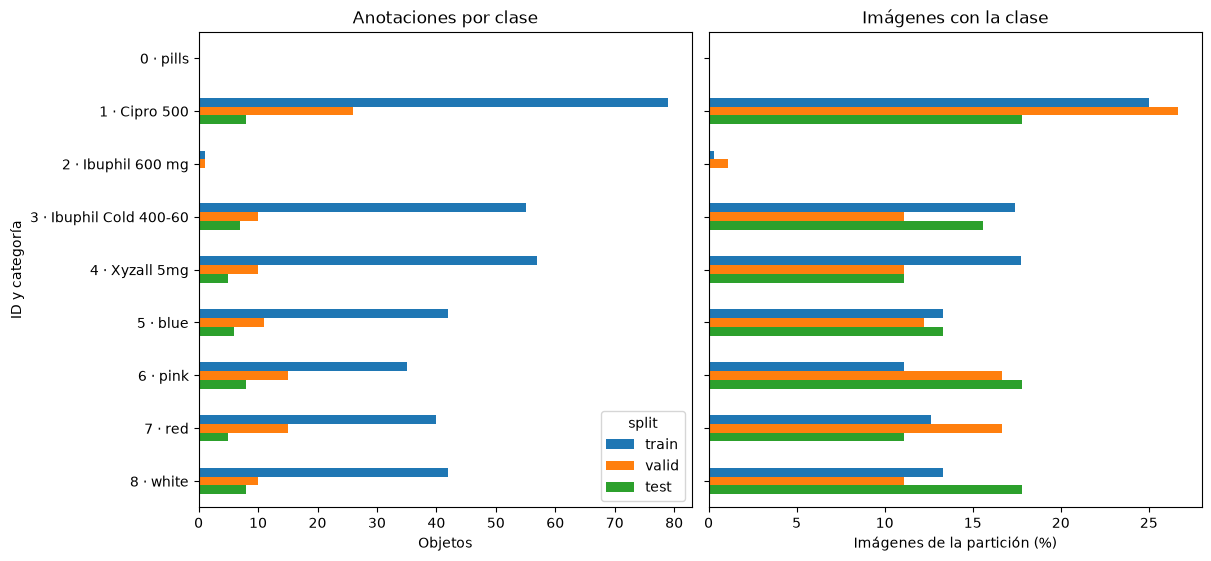

In [6]:
linked = objects[objects["known_image"] & objects["known_category"]].copy()
counts_per_image = linked.groupby(["split", "image_id"]).size().rename("objects")
image_counts = images.join(counts_per_image, on=["split", "image_id"])
image_counts["objects"] = image_counts["objects"].fillna(0).astype(int)

presence_pct = image_presence.div(audit["registros COCO"], axis="columns") * 100
display(image_presence.add_prefix("imágenes en ").join(presence_pct.round(1).add_prefix("% en ")))
display(image_counts.groupby("split")["objects"].describe().reindex(parts).round(2))
totals = category_counts.sum(axis=1)
print("Categorías con 1 a 5 objetos en total:",
      {labels[cid]: int(totals[cid]) for cid in totals.index[totals.between(1, 5)]})
print("Categorías activas ausentes en alguna partición:",
      {labels[cid]: [split for split in parts if category_counts.loc[cid, split] == 0]
       for cid in used_ids if (category_counts.loc[cid] == 0).any()})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
audit["JPEG/archivos de imagen"].plot.bar(ax=axes[0], rot=0, title="Imágenes en disco")
axes[0].bar_label(axes[0].containers[0], padding=2)
axes[0].margins(y=0.18)
axes[0].set(xlabel="", ylabel="Imágenes")
bins = np.arange(image_counts["objects"].max() + 2) - 0.5
for split in parts:
    values = image_counts.loc[image_counts["split"].eq(split), "objects"]
    axes[1].hist(values, bins=bins, weights=np.ones(len(values)) / len(values) * 100,
                 histtype="step", linewidth=2, label=split)
axes[1].set(title="Objetos por imagen", xlabel="N.º de objetos", ylabel="Imágenes de la partición (%)")
axes[1].set_xticks(range(0, len(bins) - 1, max(1, len(bins) // 12)))
axes[1].legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, layout="constrained")
category_counts.rename(index=labels).plot.barh(ax=axes[0])
presence_pct.rename(index=labels).plot.barh(ax=axes[1], legend=False)
axes[0].set(title="Anotaciones por clase", xlabel="Objetos", ylabel="ID y categoría")
axes[1].set(title="Imágenes con la clase", xlabel="Imágenes de la partición (%)", ylabel="")
axes[0].invert_yaxis()
plt.show()

size,Pequeña,Mediana,Grande
split,,,
train,31,292,28
valid,8,79,11
test,2,39,6


area_pct  aspect_ratio
split                            
test  0.1     1.494         0.612
      0.5     3.155         1.000
      0.9    10.431         1.565
train 0.1     1.065         0.591
      0.5     3.071         1.006
      0.9     9.226         1.797
valid 0.1     1.114         0.568
      0.5     3.489         1.019
      0.9    11.026         1.670

Cajas con referencias válidas omitidas del cálculo geométrico: 0


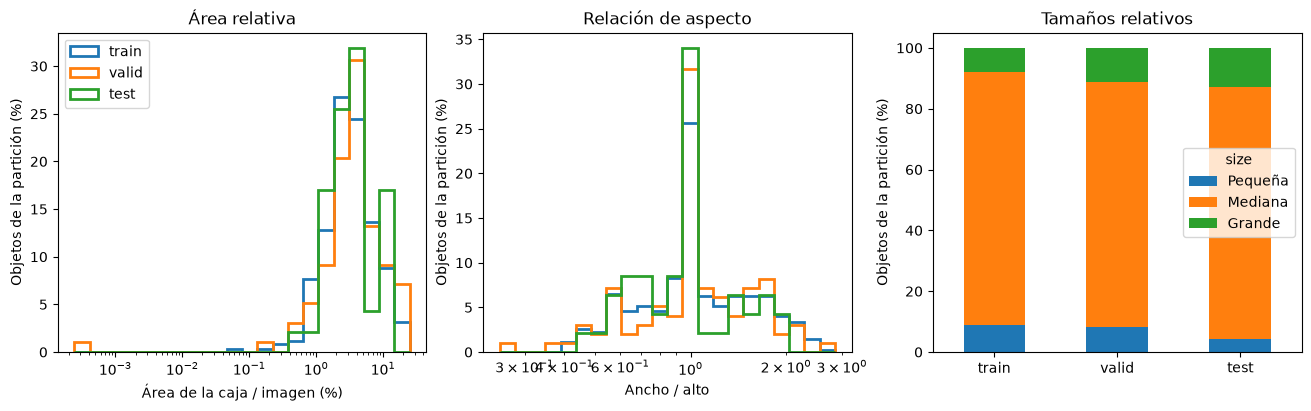

In [7]:
boxes = linked[linked["geometry"].notna()].copy()
geometry_columns = ["x", "y", "w", "h", "relative_area", "aspect_ratio"]
boxes[geometry_columns] = pd.DataFrame(
    boxes["geometry"].tolist(), columns=geometry_columns, index=boxes.index
)
boxes["size"] = pd.cut(boxes["relative_area"], [0, 0.01, 0.10, np.inf], right=False,
                       labels=["Pequeña", "Mediana", "Grande"])
size_counts = pd.crosstab(boxes["split"], boxes["size"], dropna=False).reindex(parts, fill_value=0)
display(size_counts)
metrics = (boxes.assign(area_pct=100 * boxes["relative_area"])
           .groupby("split")[["area_pct", "aspect_ratio"]].quantile([0.1, 0.5, 0.9]).round(3))
display(metrics)
print(f"Cajas con referencias válidas omitidas del cálculo geométrico: {len(linked) - len(boxes)}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, column, scale, title, xlabel in [
    (axes[0], "relative_area", 100, "Área relativa", "Área de la caja / imagen (%)"),
    (axes[1], "aspect_ratio", 1, "Relación de aspecto", "Ancho / alto"),
]:
    values = boxes[column] * scale
    edges = np.geomspace(values.min(), max(values.max(), values.min() * 1.01), 23)
    for split in parts:
        subset = values[boxes["split"].eq(split)]
        ax.hist(subset, bins=edges, weights=np.ones(len(subset)) / len(subset) * 100,
                histtype="step", linewidth=2, label=split)
    ax.set(xscale="log", title=title, xlabel=xlabel, ylabel="Objetos de la partición (%)")
axes[0].legend()
size_counts.div(size_counts.sum(axis=1), axis=0).mul(100).plot.bar(
    stacked=True, ax=axes[2], rot=0, title="Tamaños relativos"
)
axes[2].set(xlabel="", ylabel="Objetos de la partición (%)")
plt.show()

## C · Inspección visual

El selector de clase filtra las imágenes que la contienen. En cada imagen se muestran todas sus anotaciones, y las etiquetas y cajas se pueden alternar por separado. El botón aleatorio usa la semilla y un contador de pulsaciones que se reinicia al cambiar la semilla, el filtro o la partición. La misma secuencia de pulsaciones reproduce la misma selección.

El visor actualiza un solo panel y abre una imagen cada vez. El índice incluye todos los archivos decodificables de la partición, incluso si alguno carece de anotaciones.

In [8]:
colors = {cid: plt.get_cmap("tab10")(i % 10) for i, cid in enumerate(class_ids)}
boxes_by_image = {key: group for key, group in boxes.groupby(["split", "image_id"])}
file_classes = defaultdict(set)
file_keys = {}
for image in images.itertuples(index=False):
    if image.readable:
        file_keys.setdefault((image.split, image.file_name), image.image_id)
for row in linked.itertuples(index=False):
    file_classes[(row.split, row.image_id)].add(row.category_id)
catalog = {split: list(image_files[image_files["split"].eq(split)].itertuples(index=False))
           for split in parts}

def draw_example(ax, split, file_name, show_boxes=True, show_labels=True):
    with Image.open(root / split / file_name) as source:
        width, height = source.size
        ax.imshow(source.convert("RGB"), extent=(0, width, height, 0))
    ax.set_axis_off()
    image_id = file_keys.get((split, file_name))
    group = boxes_by_image.get((split, image_id))
    if group is None:
        return
    for box in group.itertuples(index=False):
        color = colors[box.category_id]
        if show_boxes:
            ax.add_patch(Rectangle((box.x, box.y), box.w, box.h, fill=False,
                                   edgecolor=color, linewidth=2))
        if show_labels:
            ax.text(box.x, box.y, category_names[box.category_id], color="white",
                    fontsize=8, va="top", bbox={"facecolor": color, "edgecolor": "none", "pad": 2})

In [9]:
split_picker = widgets.Dropdown(options=list(parts), description="Partición")
class_picker = widgets.Dropdown(options=[("Todas", None), *[(labels[cid], cid) for cid in class_ids]],
                                description="Clase")
index_picker = widgets.IntSlider(min=1, max=1, description="Imagen", continuous_update=False)
previous = widgets.Button(description="Anterior")
following = widgets.Button(description="Siguiente")
random_button = widgets.Button(description="Aleatoria")
seed_picker = widgets.IntText(value=SEED, description="Semilla")
show_boxes = widgets.Checkbox(value=True, description="Cajas", indent=False)
show_labels = widgets.Checkbox(value=True, description="Etiquetas", indent=False)
picture = widgets.Image(format="png", layout=widgets.Layout(width="min(100%, 540px)"))
info = widgets.HTML()
output_panel = widgets.VBox([info, picture])
selection = []
rng = Random(SEED)

def render(_=None):
    index = index_picker.value - 1
    previous.disabled = not selection or index == 0
    following.disabled = not selection or index >= len(selection) - 1
    if not selection:
        picture.value = b""
        picture.layout.display = "none"
        info.value = "No hay imágenes que coincidan con el filtro."
        return
    row = selection[index]
    image_id = file_keys.get((row.split, row.file_name))
    classes = ", ".join(labels[cid] for cid in sorted(file_classes[(row.split, image_id)]))
    image_id_text = str(image_id) if image_id is not None else "sin registro COCO"
    fig = Figure(figsize=(5.5, 5.5))
    ax = fig.add_axes([0, 0, 1, 1])
    draw_example(ax, row.split, row.file_name, show_boxes.value, show_labels.value)
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=100)
    picture.value = buffer.getvalue()
    picture.layout.display = ""
    info.value = (
        f"<b>{row.split} · {index + 1}/{len(selection)}</b> · ID {image_id_text} · "
        f"{row.width} × {row.height} px<br>{escape(row.file_name)}<br>"
        f"Clases: {escape(classes or 'sin anotaciones')}"
    )

def reset_random(_=None):
    rng.seed(seed_picker.value)

def refresh_selection(_=None):
    split = split_picker.value
    cid = class_picker.value
    selection[:] = [row for row in catalog[split] if cid is None or
                    cid in file_classes[(split, file_keys.get((split, row.file_name)))]]
    index_picker.unobserve(render, names="value")
    index_picker.value = 1
    index_picker.max = max(1, len(selection))
    index_picker.disabled = random_button.disabled = not selection
    index_picker.observe(render, names="value")
    reset_random()
    render()

def pick_random(_):
    if selection:
        index_picker.value = rng.randrange(1, len(selection) + 1)

previous.on_click(lambda _: setattr(index_picker, "value", index_picker.value - 1))
following.on_click(lambda _: setattr(index_picker, "value", index_picker.value + 1))
random_button.on_click(pick_random)
seed_picker.observe(reset_random, names="value")
for picker in (split_picker, class_picker):
    picker.observe(refresh_selection, names="value")
for toggle in (index_picker, show_boxes, show_labels):
    toggle.observe(render, names="value")
refresh_selection()
display(widgets.VBox([
    widgets.HBox([split_picker, class_picker]),
    widgets.HBox([previous, following, index_picker]),
    widgets.HBox([seed_picker, random_button, show_boxes, show_labels]),
    output_panel,
]))

In [10]:
def show_multi_object_images():
    rows = []
    for split in parts:
        for row in catalog[split]:
            image_id = file_keys.get((split, row.file_name))
            object_count = len(boxes_by_image.get((split, image_id), ()))
            if object_count >= 2:
                rows.append((row, image_id, object_count))
    if not rows:
        print("No hay imágenes legibles con al menos dos cajas anotadas válidas.")
        return

    index_picker = widgets.IntSlider(
        min=1, max=len(rows), description="Imagen", continuous_update=False
    )
    previous = widgets.Button(description="Anterior")
    following = widgets.Button(description="Siguiente")
    show_boxes = widgets.Checkbox(value=True, description="Cajas", indent=False)
    show_labels = widgets.Checkbox(value=True, description="Etiquetas", indent=False)
    picture = widgets.Image(format="png", layout=widgets.Layout(width="min(100%, 540px)"))
    info = widgets.HTML()

    def render(_=None):
        index = index_picker.value
        row, image_id, object_count = rows[index - 1]
        previous.disabled = index == 1
        following.disabled = index == len(rows)
        classes = ", ".join(labels[cid] for cid in sorted(file_classes[(row.split, image_id)]))
        info.value = (
            f"<b>{row.split} · {index}/{len(rows)}</b> · ID {image_id} · "
            f"{object_count} objetos<br>{escape(row.file_name)}<br>Clases: {escape(classes)}"
        )
        fig = Figure(figsize=(5.5, 5.5))
        ax = fig.add_axes([0, 0, 1, 1])
        draw_example(ax, row.split, row.file_name, show_boxes.value, show_labels.value)
        with BytesIO() as buffer:
            fig.savefig(buffer, format="png", dpi=100)
            picture.value = buffer.getvalue()

    previous.on_click(lambda _: setattr(index_picker, "value", index_picker.value - 1))
    following.on_click(lambda _: setattr(index_picker, "value", index_picker.value + 1))
    for control in (index_picker, show_boxes, show_labels):
        control.observe(render, names="value")
    render()
    display(widgets.VBox([
        widgets.HTML("<b>Imágenes con varios objetos</b>"),
        widgets.HBox([previous, following, index_picker]),
        widgets.HBox([show_boxes, show_labels]),
        info,
        picture,
    ]))


show_multi_object_images()

La cuadrícula elige una imagen por categoría usada. Busca la caja más cercana a la mediana del área relativa de su clase entre las imágenes legibles. Es una muestra orientativa que no cubre toda la variabilidad.

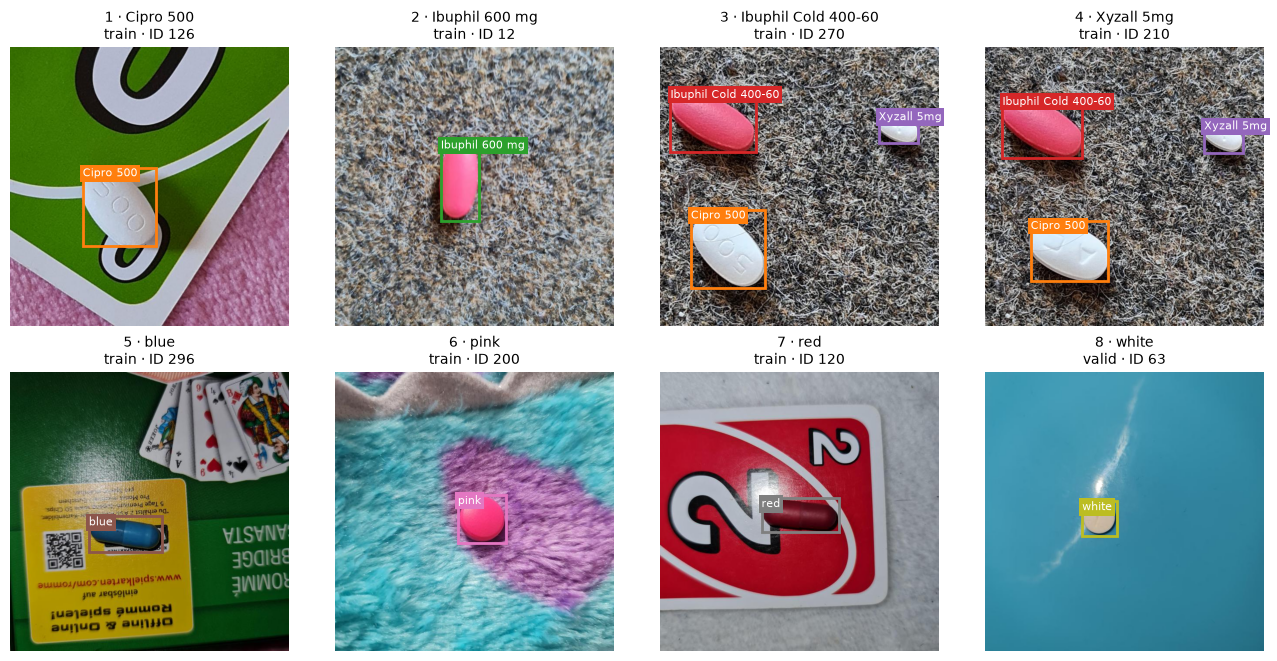

In [11]:
examples = boxes.merge(
    images[images["readable"]][["split", "image_id", "file_name"]].drop_duplicates(["split", "image_id"]),
    on=["split", "image_id"],
)
if examples.empty:
    print("No hay cajas válidas en imágenes legibles para la cuadrícula.")
else:
    fig, axes = plt.subplots(math.ceil(examples["category_id"].nunique() / 4), 4,
                             figsize=(13, 6.5), squeeze=False, layout="constrained")
    for ax in axes.flat:
        ax.set_axis_off()
    for ax, (cid, group) in zip(axes.flat, examples.groupby("category_id")):
        row = group.loc[(group["relative_area"] - group["relative_area"].median()).abs().idxmin()]
        draw_example(ax, row["split"], row["file_name"])
        ax.set_title(f"{labels[cid]}\n{row['split']} · ID {row['image_id']}", fontsize=10)
    plt.show()

## D · Características visuales

Por imagen medimos la luminancia aproximada de Pillow (`L`, escala 0–255), su desviación típica como contraste global y el gradiente absoluto medio entre píxeles vecinos. El gradiente también responde a bordes, textura y compresión, por lo que solo orienta la inspección de nitidez. El tamaño JPEG depende del contenido y de la compresión. Revisamos la resolución decodificada y comparamos las distribuciones RGB mediante histogramas donde cada imagen pesa lo mismo dentro de su partición.

Son medidas de la imagen completa e incluyen el fondo. Un valor extremo puede venir de la escena, de la iluminación o del procesamiento de origen. Las imágenes de la cuadrícula y el visor ayudan a interpretar los valores.

,,,,imágenes
split,width,height,format,
test,640,640,JPEG,45
train,640,640,JPEG,316
valid,640,640,JPEG,90


Luminosidad media (0–255)  Contraste global (desv. típica)  \
split                                                                   
test  0.1                      96.84                            17.08   
      0.5                     128.80                            38.16   
      0.9                     152.41                            60.03   
train 0.1                      97.07                            18.23   
      0.5                     136.32                            35.51   
      0.9                     162.40                            61.01   
valid 0.1                      90.89                            19.37   
      0.5                     128.27                            36.37   
      0.9                     159.73                            64.75   

           Gradiente absoluto medio  Tamaño de archivo (KiB)  
split                                                         
test  0.1                      1.94                    32.82  
      0.5                      3.73                    46.81  
      0.9                     12.17                    92.77  
train 0.1                      1.18                    24.19  
      0.5                      3.50                    47.13  
      0.9                     11.84                    91.15  
valid 0.1                      1.24                    27.82  
      0.5                      2.97                    42.60  
      0.9                     12.40                    94.43

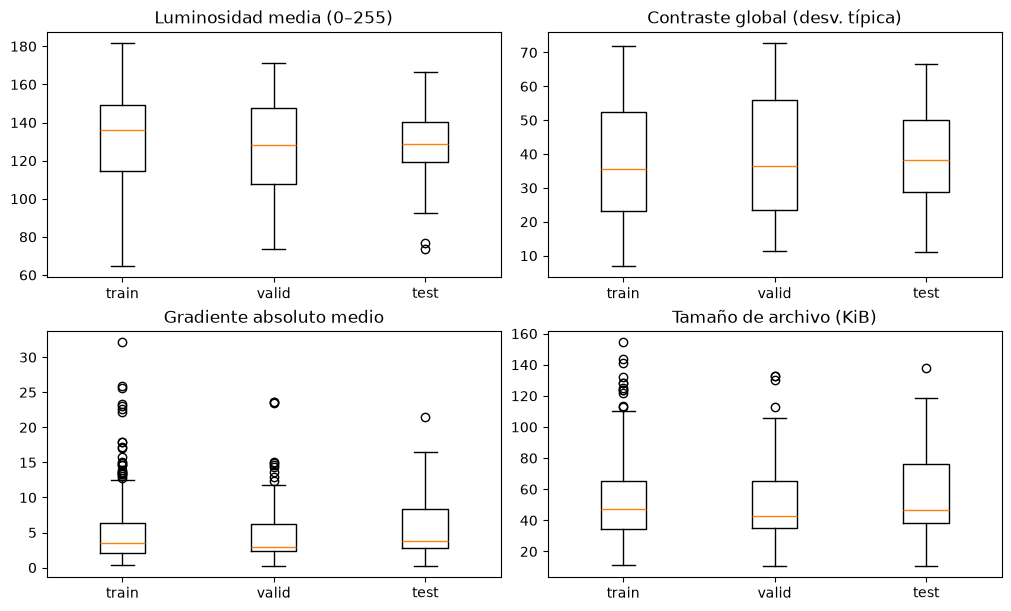

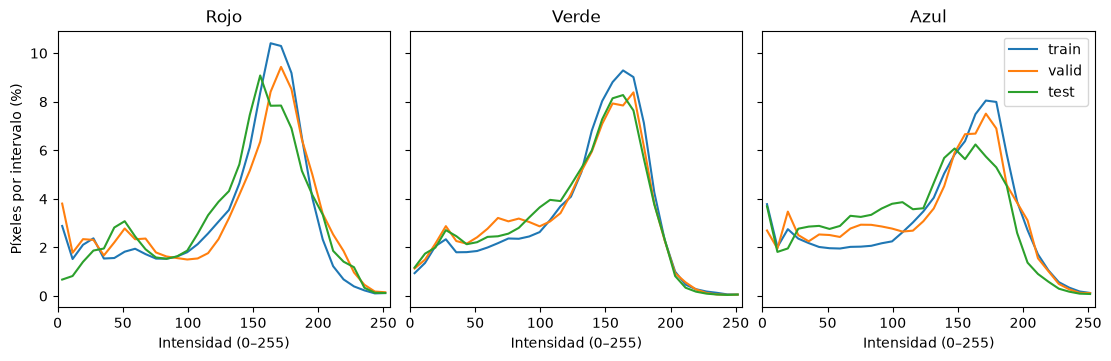

In [12]:
resolutions = (image_files.groupby(["split", "width", "height", "format"])
               .size().rename("imágenes").to_frame())
display(resolutions)

visual_metrics = {
    "brightness": "Luminosidad media (0–255)",
    "contrast": "Contraste global (desv. típica)",
    "gradient": "Gradiente absoluto medio",
    "size_kib": "Tamaño de archivo (KiB)",
}
display(image_files.groupby("split")[list(visual_metrics)]
        .quantile([0.1, 0.5, 0.9]).rename(columns=visual_metrics).round(2))
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for ax, (column, title) in zip(axes.flat, visual_metrics.items()):
    ax.boxplot([image_files.loc[image_files["split"].eq(split), column].dropna()
                for split in parts], tick_labels=list(parts))
    ax.set_title(title)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True, layout="constrained")
centers = np.arange(32) * 8 + 3.5
for channel, (ax, title) in enumerate(zip(axes, ["Rojo", "Verde", "Azul"])):
    for split in parts:
        count = audit.loc[split, "decodificadas"]
        if count:
            ax.plot(centers, 100 * rgb_histograms[split][channel] / count, label=split)
    ax.set(title=title, xlabel="Intensidad (0–255)", xlim=(0, 255))
axes[0].set_ylabel("Píxeles por intervalo (%)")
axes[-1].legend()
plt.show()

## E · Conclusiones

El resumen se calcula a partir de los datos leídos en esta ejecución. Las incidencias detalladas y los candidatos a duplicados quedan en las tablas anteriores.

In [13]:
active_counts = totals.loc[used_ids]
rare = ", ".join(
    f"{labels[cid]} ({int(totals[cid])} objetos)" for cid in active_counts.index[active_counts.le(5)]
) or "ninguna"
inactive = ", ".join(labels[cid] for cid in class_ids if cid not in used_ids) or "ninguna"
absent_from_test = ", ".join(labels[cid] for cid in used_ids if category_counts.loc[cid, "test"] == 0) or "ninguna"
jpeg_groups = repeated_groups("sha256")
rgb_groups = repeated_groups("pixel_hash")
display(Markdown(
    f"- **Cobertura.** Se decodificaron {len(image_files)} imágenes y se leyeron {len(objects)} anotaciones. "
    f"COCO declara {len(class_ids)} categorías y usa {len(used_ids)}, frente a las siete clases del guion. "
    f"Declaradas sin anotaciones: {inactive}.\n"
    f"- **Desbalance.** Categorías activas con hasta cinco objetos: {rare}. "
    f"Categorías activas ausentes en test: {absent_from_test}.\n"
    f"- **Calidad.** La auditoría registró {len(issue_table)} incidencias. "
    f"Hay {len(jpeg_groups)} grupos de JPEG idénticos, {len(rgb_groups)} de píxeles idénticos y "
    f"{len(visual_pairs)} pares candidatos a duplicado visual, {visual_cross} entre particiones.\n"
    f"- **Resolución.** Dimensiones observadas: " + ", ".join(
        f"{w}×{h} px" for w, h in sorted(set(zip(image_files['width'], image_files['height'])))
    ) + "."
))

- **Cobertura.** Se decodificaron 451 imágenes y se leyeron 496 anotaciones. COCO declara 9 categorías y usa 8, frente a las siete clases del guion. Declaradas sin anotaciones: 0 · pills.
- **Desbalance.** Categorías activas con hasta cinco objetos: 2 · Ibuphil 600 mg (2 objetos). Categorías activas ausentes en test: 2 · Ibuphil 600 mg.
- **Calidad.** La auditoría registró 0 incidencias. Hay 0 grupos de JPEG idénticos, 0 de píxeles idénticos y 6 pares candidatos a duplicado visual, 3 entre particiones.
- **Resolución.** Dimensiones observadas: 640×640 px.

El tamaño de las particiones y el escaso soporte de algunas categorías limitan las comparaciones por clase. Las comprobaciones automáticas no certifican que todas las cajas rodeen correctamente una pastilla ni que las etiquetas sean correctas. Los candidatos dHash deben revisarse manualmente.

Como hipótesis para más adelante, se puede comprobar si el rendimiento cambia con el tamaño relativo de las cajas y si las imágenes poco iluminadas concentran errores antes de justificar aumentos fotométricos. Como algunas categorías se distinguen por color, cualquier cambio cromático debería evaluarse por clase. Quedan pendientes la revisión visual de los casos señalados y la aclaración de la discrepancia de categorías con el guion.

### Observaciones preliminares para el entrenamiento

- **Tamaño del dataset.** Se decodificaron 451 imágenes: 316 en `train`, 90 en `valid` y 45 en `test`. El tamaño de `train` puede favorecer el sobreajuste durante el fine-tuning, y unos pocos errores pueden mover las métricas de `test`. Comparar un ajuste parcial con uno completo en validación ayudaría a decidir cuántos parámetros entrenar.
- **Luminosidad.** La mediana de la luminancia media por imagen fue ligeramente mayor en `train` (136,32) que en `valid` (128,27) y `test` (128,80), en una escala de 0 a 255. Es una diferencia descriptiva. Si los errores se concentran en imágenes más oscuras, tendría sentido probar aumentos fotométricos que varíen el brillo y contrastar su efecto en validación.
- **Similitud entre particiones.** Los recuentos de grupos con archivos o píxeles idénticos fueron cero. dHash señaló seis pares candidatos a similitud perceptual, tres entre particiones (dos `train`–`valid` y uno `train`–`test`). Si la revisión visual confirma que muestran la misma escena u objeto en tomas casi iguales, su presencia en distintas particiones podría inflar las métricas. En ese caso, agrupar esas tomas en una sola partición ayudaría a preservar la independencia de la evaluación.
- **Imágenes con varios objetos.** Hay 23 imágenes con al menos dos cajas: 19 de 316 en `train`, 3 de 90 en `valid` y 1 de 45 en `test`. La escasez de estos casos limita la evaluación de omisiones de instancias. Si la revisión de errores muestra dificultades en estas escenas, se podría ampliar su cobertura en el entrenamiento.
- **Clases y tamaños.** `Ibuphil 600 mg` tiene una anotación en `train`, una en `valid` y ninguna en `test`. Su escaso soporte puede dificultar el aprendizaje y deja su rendimiento sin medir en `test`. La mayoría de las cajas son medianas según los cortes del EDA, y solo dos cajas de `test` ocupan menos del 1 % de la imagen. Revisar los errores por tamaño en validación ayudaría a decidir si merece la pena probar otra resolución de entrada.